# 04 · Segmentación de clientes con K-Means

K-Means es **no supervisado**: agrupa clientes por similitud de sus 25 características sin ver si
abandonaron. No predice el abandono (eso lo hacen la logística y la red, notebook 05); su aporte es
dar perfiles accionables para diseñar estrategias por grupo.

El modelo lo entrena `pipeline/train_kmeans.py` (la API lo usa). Este notebook carga ese modelo y sus
tablas, y explica las decisiones:
1. Escala 0-1 (MinMax): K-Means usa distancias; sin escalar, el cargo acumulado (miles de USD)
   dominaría frente a variables 0/1.
2. k entre 2 y 8: mayor silueta entre los k estables (ARI ≥ 0,95 al cambiar la semilla).
3. El abandono se cruza **después** de agrupar, para ordenar los segmentos de mayor a menor riesgo.

Salidas: `ml/reports/figures/segmentacion/*.png`

In [1]:
import sys

sys.path.insert(0, "..")

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.train_kmeans import MIN_STABILITY, assign
from telco import paths, style
from telco.data import NUMERIC, load_clean
from telco.style import INK, LABELS, MUTED, SEG_COLORS

style.apply()
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

df = load_clean()
y = df["churn"]
bundle = joblib.load(paths.KMEANS_MODEL)
meta = json.loads(paths.KMEANS_META.read_text())
X = df[meta["feature_columns"]]
Z = bundle["scaler"].transform(X)
seg = assign(bundle, X)
ksel = pd.read_csv(paths.TABLES / "clusters_k.csv")
table = pd.read_csv(paths.TABLES / "clusters_segmentos.csv")
K = len(table)
NAMES = {s["id"]: s["name"] for s in meta["segments"]}
colors = [SEG_COLORS[s - 1] for s in range(1, K + 1)]
assert (pd.Series(seg).value_counts().sort_index().values == table.clientes.values).all()

## 1. Elección de k
k = 4 y k = 5 quedan muy cerca (silueta 0,168 frente a 0,165); 7 y 8 no son estables. Una silueta
de 0,168 indica separación modesta, pero el ARI ≈ 1 muestra que los grupos se reproducen con
cualquier semilla.

,k,silueta,estabilidad_ari
0,2,0.149,0.971
1,3,0.154,0.970
2,4,0.168,1.000
3,5,0.165,0.999
4,6,0.132,0.975
5,7,0.148,0.864
6,8,0.131,0.866


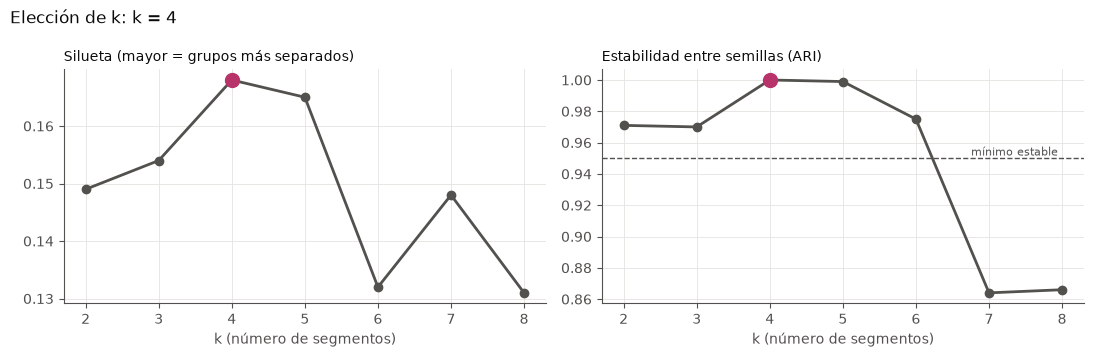

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axes[0], "silueta", "Silueta (mayor = grupos más separados)"),
                       (axes[1], "estabilidad_ari", "Estabilidad entre semillas (ARI)")]:
    ax.plot(ksel.k, ksel[col], color=MUTED, lw=2, marker="o", ms=6)
    ax.plot(K, ksel.set_index("k").loc[K, col], marker="o", ms=10, color=SEG_COLORS[0])
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("k (número de segmentos)")
axes[1].axhline(MIN_STABILITY, color=MUTED, ls="--", lw=1)
axes[1].text(ksel.k.max(), MIN_STABILITY, "mínimo estable ", ha="right", va="bottom", color=MUTED, fontsize=8)
fig.suptitle(f"Elección de k: k = {K}", x=0.01, ha="left")
fig.tight_layout()
style.save(fig, paths.figure("segmentacion", "clusters_k.png"))
ksel

## 2. Segmentos
Cada segmento con su tasa de abandono (IC 95 % de Wilson), lift (tasa / tasa global) y cobertura
(% de todas las bajas que reúne). El ingreso en riesgo usa la probabilidad de la logística fuera
de pliegue × cargo mensual.

In [3]:
base = y.mean() * 100
view = table.assign(
    nombre=table.segmento.map(NAMES),
    lift=table.tasa_abandono / base,
    cobertura_bajas=table.clientes * table.tasa_abandono / 100 / y.sum() * 100,
)
view[["segmento", "nombre", "clientes", "pct_clientes", "tasa_abandono", "ic95_bajo", "ic95_alto", "lift",
      "cobertura_bajas", "ingreso_en_riesgo", "pct_ingreso_en_riesgo"]].round(2)

,segmento,nombre,clientes,pct_clientes,tasa_abandono,ic95_bajo,ic95_alto,lift,cobertura_bajas,ingreso_en_riesgo,pct_ingreso_en_riesgo
0,1,"Fibra, mes a mes",2160,30.67,54.03,51.92,56.12,2.04,62.44,101227.16,72.68
1,2,"DSL, mes a mes",1598,22.69,26.28,24.18,28.50,0.99,22.47,20568.53,14.77
2,3,Antiguos con contrato,1754,24.90,9.64,8.34,11.11,0.36,9.05,15070.35,10.82
3,4,Sin internet,1531,21.74,7.38,6.18,8.80,0.28,6.05,2420.95,1.74


In [4]:
for r in table.itertuples():
    print(f"{r.segmento} · {NAMES[r.segmento]}: {r.rasgos}")
print(f"\nIngreso mensual en riesgo: ${table.ingreso_en_riesgo.sum():,.0f} de ${table.ingreso_mensual.sum():,.0f}")
print(f"eta² riesgo ~ segmento: {meta['risk_eta2']:.2f} (el segmento explica esa parte de la varianza del riesgo individual)")

1 · Fibra, mes a mes: fibra óptica 100% (total 44%); mes a mes 96% (total 55%); DSL 0% (total 34%); cheque electrónico 63% (total 34%)
2 · DSL, mes a mes: DSL 100% (total 34%); fibra óptica 0% (total 44%); múltiples líneas 15% (total 42%); línea telefónica 67% (total 90%)
3 · Antiguos con contrato: mes a mes 4% (total 55%); protección equipo 76% (total 34%); soporte técnico 68% (total 29%); streaming películas 77% (total 39%)
4 · Sin internet: sin internet 100% (total 22%); fibra óptica 0% (total 44%); cargo mensual ($) 20 (total 70); streaming películas 0% (total 39%)

Ingreso mensual en riesgo: $139,287 de $456,117
eta² riesgo ~ segmento: 0.66 (el segmento explica esa parte de la varianza del riesgo individual)


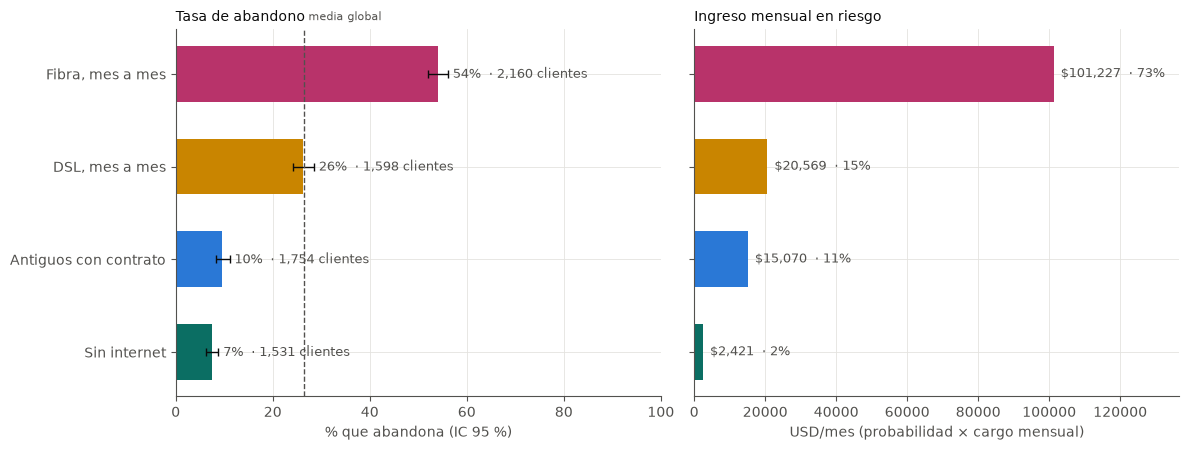

In [5]:
t = table.iloc[::-1]
yy = np.arange(K)
fig, axes = plt.subplots(1, 2, figsize=(12, 0.7 * K + 1.8), sharey=True)
ax = axes[0]
ax.barh(yy, t.tasa_abandono, color=colors[::-1], height=0.6)
ax.errorbar(t.tasa_abandono, yy, xerr=[t.tasa_abandono - t.ic95_bajo, t.ic95_alto - t.tasa_abandono],
            fmt="none", ecolor=INK, elinewidth=1, capsize=3)
ax.axvline(base, color=MUTED, ls="--", lw=1)
ax.text(base, K - 0.45, " media global", color=MUTED, fontsize=8, va="bottom")
for yi, r in zip(yy, t.itertuples()):
    ax.text(r.ic95_alto + 1, yi, f"{r.tasa_abandono:.0f}%  · {r.clientes:,} clientes", va="center", color=MUTED, fontsize=9)
ax.set_yticks(yy, [NAMES[s] for s in t.segmento])
ax.set_xlim(0, 100)
ax.set_xlabel("% que abandona (IC 95 %)")
ax.set_title("Tasa de abandono", loc="left", fontsize=10)
ax = axes[1]
ax.barh(yy, t.ingreso_en_riesgo, color=colors[::-1], height=0.6)
for yi, r in zip(yy, t.itertuples()):
    ax.text(r.ingreso_en_riesgo + table.ingreso_en_riesgo.max() * 0.02, yi,
            f"${r.ingreso_en_riesgo:,.0f}  · {r.pct_ingreso_en_riesgo:.0f}%", va="center", color=MUTED, fontsize=9)
ax.set_xlim(0, table.ingreso_en_riesgo.max() * 1.35)
ax.set_xlabel("USD/mes (probabilidad × cargo mensual)")
ax.set_title("Ingreso mensual en riesgo", loc="left", fontsize=10)
fig.tight_layout()
style.save(fig, paths.figure("segmentacion", "clusters_abandono_ingreso.png"))

## 3. Mapa 2D (PCA)
Proyecta las 25 variables en 2 dimensiones para visualizar los grupos. Conserva solo parte de la
variación, por eso hay solapamiento visual aunque cada cliente pertenece a un único segmento.

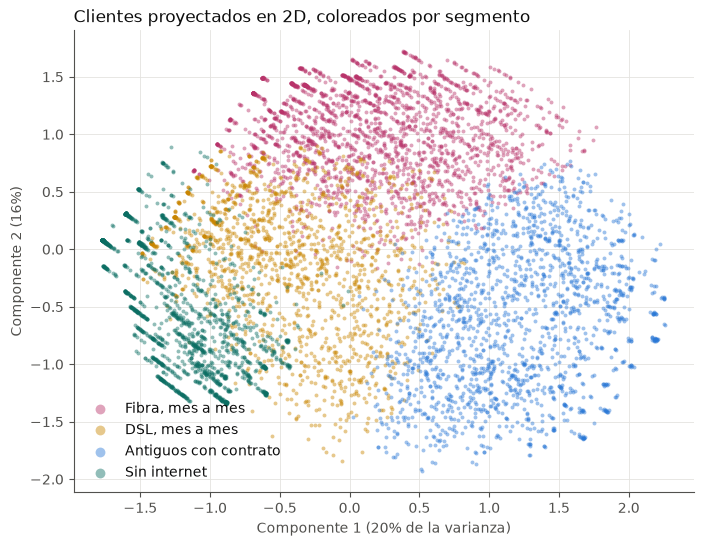

In [6]:
pca = bundle["pca"]
P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(8, 6))
for s, c in zip(range(1, K + 1), colors):
    m = seg == s
    ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.45, color=c, linewidths=0, label=NAMES[s])
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Clientes proyectados en 2D, coloreados por segmento", loc="left")
ax.legend(frameon=False, markerscale=2.5)
style.save(fig, paths.figure("segmentacion", "clusters_mapa.png"))

## 4. Perfil de cada segmento
% de clientes con cada característica (mediana en antigüedad y cargo mensual). El color usa la
escala 0-1 con la que agrupa K-Means.

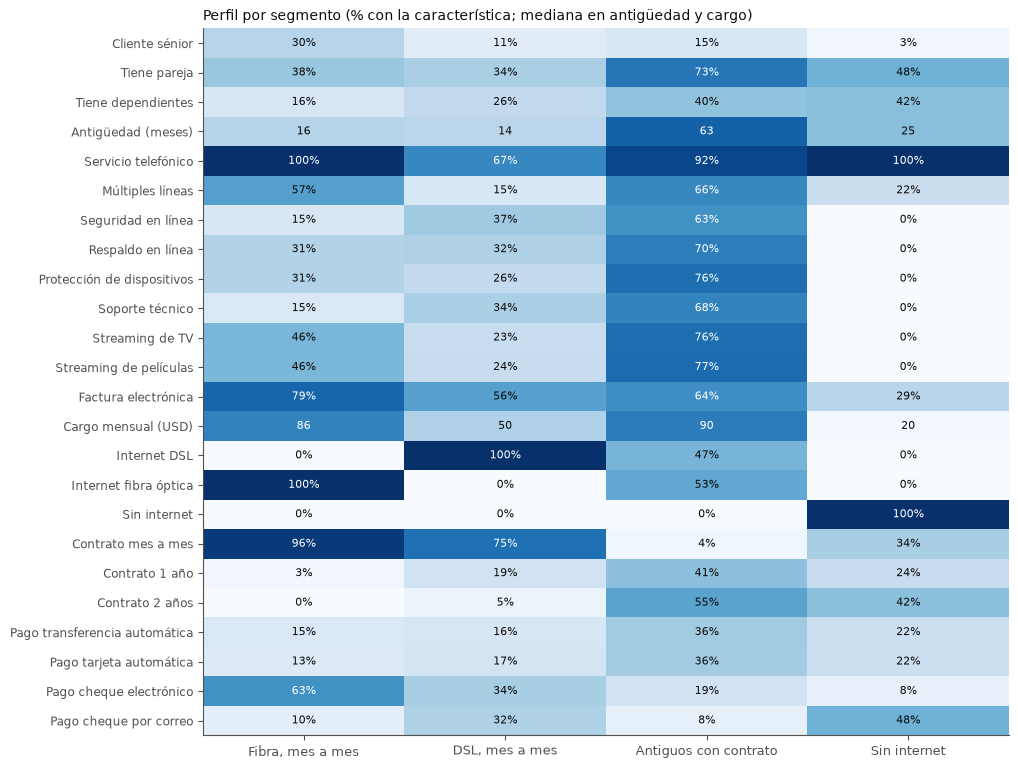

In [7]:
prof_cols = [c for c in X.columns if c != "total_charges"]
Zdf = pd.DataFrame(Z, columns=X.columns)
prof = pd.DataFrame({NAMES[s]: Zdf[seg == s][prof_cols].mean() for s in range(1, K + 1)})
shown = pd.DataFrame({NAMES[s]: [X[seg == s][c].median() if c in NUMERIC else X[seg == s][c].mean() * 100
                                 for c in prof_cols] for s in range(1, K + 1)}, index=prof_cols)
fig, ax = plt.subplots(figsize=(1.6 * K + 4, 0.32 * len(prof_cols) + 1.5))
ax.imshow(prof.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.grid(False)
for i, c in enumerate(prof_cols):
    for j in range(K):
        v = shown.iat[i, j]
        ax.text(j, i, f"{v:.0f}" if c in NUMERIC else f"{v:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if prof.iat[i, j] > 0.6 else INK)
ax.set_xticks(range(K), prof.columns, fontsize=9)
ax.set_yticks(range(len(prof_cols)), [LABELS[c] for c in prof_cols], fontsize=8.5)
ax.set_title("Perfil por segmento (% con la característica; mediana en antigüedad y cargo)", loc="left", fontsize=10)
style.save(fig, paths.figure("segmentacion", "clusters_perfil.png"))

## 5. Qué distingue a quien se va dentro de un segmento
Todo el segmento «Fibra, mes a mes» tiene fibra, así que la fibra **caracteriza** al grupo pero no
explica quién se va dentro de él. La antigüedad sí lo separa.

In [8]:
fiber = df[seg == 1]
fiber.groupby("churn")[["tenure", "monthly_charges"]].median().rename(index={0: "Se queda", 1: "Abandona"})

,tenure,monthly_charges
churn,,
Se queda,25.0,86.45
Abandona,10.0,85.35
